# 23 — Khởi tạo QAOA: điểm hiện tại, multistart và INTERP

**Bước 2: một input a3_dev_n5, 5 task + 3 host, 25 qubit.** Giữ domain-wall, penalty 4, X mixer, max_abs, COBYLA và mean-energy. Huấn luyện exact để tách ảnh hưởng khởi tạo khỏi nhiễu shots.

Mỗi kết quả chiến lược có **trần tổng 200 đánh giá hàm**. Phần tối ưu p=1 để tạo điểm INTERP cũng được tính vào 200. Có 13 kết quả chiến lược, gồm 24 lượt optimizer. Bộ đếm nfev thực tế vẫn được báo vì optimizer có thể dừng sớm.

Đọc `N23_README_FIRST.md`. Bản bàn giao chưa chạy; QA không phải kết quả chiến dịch chính. Không dùng góc hoặc kết quả đã học từ Notebook 22 làm đầu vào của chiến lược mới.

## 1. Môi trường và cấu hình phiên chạy

Lần đầu giữ RESUME_DIR=None. Khi tiếp tục, nhập đúng campaign cũ. MAX_NEW_TRIALS chia nhỏ số lượt optimizer trong một phiên, không đổi ngân sách chiến lược. TARGET_GROUPS chỉ chọn lịch chạy từ kế hoạch, không bỏ nhóm khác khỏi kết quả partial. Mặc định chạy toàn bộ.

In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'src/initialization_campaign.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Chép đủ gói Notebook23 vào thư mục gốc repo.')
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))
from src.initialization_campaign import (PROTOCOL, load_json, identity, make_plan,
    create_campaign, prepare_campaign, run_campaign, summarize, export_campaign)

RESUME_DIR = None
MAX_NEW_TRIALS = None  # Ví dụ 1 để chia nhỏ phiên.
TARGET_GROUPS = None  # Nâng cao: ví dụ ['p2__interp']; kế hoạch vẫn giữ đủ nhóm.
PREPARE_ONLY = False  # True: chỉ đo chi phí trước; lần sau phải resume.

print('Python:',sys.executable)
print('Repo:',ROOT)

Python: c:\Users\Khiem\anaconda3\envs\nt409-khiem\python.exe
Repo: c:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement


## 2. Kế hoạch cố định và quy tắc chọn kết quả

| Chiến lược | p | Cách dùng ngân sách | Số kết quả |
|---|---|---|---:|
| single | 1,2 | Một điểm hiện tại, cap 200 | 1 mỗi p |
| multistart | 1,2 | Điểm hiện tại 100 + một điểm ngẫu nhiên 100 | 5 mỗi p |
| INTERP | 2 | Tối ưu p=1 cap 100; lặp beta/gamma sang p=2, cap 100 | 1 |

Tổng 13 kết quả chiến lược, 24 lượt optimizer, tối đa 2600 đánh giá hàm. Các điểm random được quyết định trước từ seed 400–404. Beta được lấy trên [0,π), gamma_execution trên [0,2π×scale); kế hoạch lưu góc thực dùng.

INTERP(1→2): [beta,gamma] → [beta,beta,gamma,gamma], theo Zhou et al., PRX 10,021067 (2020), Phụ lục B Eq.B1. Đây là phiên bản có ngân sách; p=1 có thể chưa hội tụ khi hết 100.

Multistart chọn điểm trả về có **mean-energy exact thấp nhất**. P_opt chỉ chấm sau đó, không chọn lại theo đáp án. Với INTERP chỉ điểm p=2 là kết quả đích; p=1 là phần chuẩn bị có tính phí.

In [2]:
protocol = load_json(ROOT/PROTOCOL)
ident = identity(ROOT,protocol)
plan = make_plan(protocol,ident['model']['scale'])
instance = next(iter(ident['inputs'].values()))
display(pd.DataFrame(instance['tasks']))
display(pd.DataFrame(instance['hosts']))
print('Model:',ident['model'])
print('Runtime:',ident['runtime'])
print('software_validation:',protocol['software_validation'])
display(pd.DataFrame([dict(id=t['id'],group=t['group'],target_depth=t['target_depth'],
    stage_depth=t['p'],start=t['start'],cap=t['config']['maxiter'],
    initial_point=t['config']['initial_point'],depends_on=t['depends_on']) for t in plan]))
print('Groups:',len(set(t['group'] for t in plan)),'| optimizer trials:',len(plan))
print('Tổng trần đánh giá:',sum(t['config']['maxiter'] for t in plan))

,id,cpu,ram
0,t0,1,1
1,t1,1,1
2,t2,1,1
3,t3,1,1
4,t4,1,2


,id,cpu,ram
0,h0,2,2
1,h1,3,3
2,h2,3,3


Model: {'qubits': 25, 'scale': 65.5}
Runtime: {'python_version': '3.12.14', 'platform': 'Windows-11-10.0.26200-SP0', 'numpy_version': '2.5.3', 'scipy_version': '1.18.1', 'qiskit_version': '2.5.2', 'qiskit_optimization_version': '0.7.0', 'qiskit_aer_version': '0.17.2'}
software_validation: False


,id,group,target_depth,stage_depth,start,cap,initial_point,depends_on
0,p1__single__stage1,p1__single,1,1,anchor,200,"[0.3, 1.0]",NaN
1,p1__multistart_400__stage1,p1__multistart_400,1,1,anchor,100,"[0.3, 1.0]",NaN
2,p1__multistart_400__stage2,p1__multistart_400,1,1,random,100,"[1.5407720742996573, 364.91921233802424]",NaN
3,p1__multistart_401__stage1,p1__multistart_401,1,1,anchor,100,"[0.3, 1.0]",NaN
4,p1__multistart_401__stage2,p1__multistart_401,1,1,random,100,"[0.1008472270541352, 43.12997725078622]",NaN
5,p1__multistart_402__stage1,p1__multistart_402,1,1,anchor,100,"[0.3, 1.0]",NaN
6,p1__multistart_402__stage2,p1__multistart_402,1,1,random,100,"[1.0393243631933966, 391.79181527043863]",NaN
7,p1__multistart_403__stage1,p1__multistart_403,1,1,anchor,100,"[0.3, 1.0]",NaN
8,p1__multistart_403__stage2,p1__multistart_403,1,1,random,100,"[1.5568773009824295, 80.2086779159947]",NaN
9,p1__multistart_404__stage1,p1__multistart_404,1,1,anchor,100,"[0.3, 1.0]",NaN


Groups: 13 | optimizer trials: 24
Tổng trần đánh giá: 2600


## 3. Kiểm thử phần mềm trước chạy

Chạy kiểm tra bằng đúng Python của kernel: ngân sách, chọn theo năng lượng, INTERP, seed, lưu/resume và phát hiện báo cáo bị sửa. Dùng fixture nhỏ trong thư mục tạm, không thuộc dữ liệu nghiên cứu. Nếu lỗi, giữ traceback và dừng.

In [3]:
check = subprocess.run([sys.executable,'-m','unittest','discover','-s','tests',
    '-p','test_initialization*.py'],cwd=ROOT,text=True,capture_output=True)
print(check.stdout)
print(check.stderr)
check.check_returncode()


c:\Users\Khiem\anaconda3\envs\nt409-khiem\Lib\site-packages\qiskit\circuit\library\n_local\evolved_operator_ansatz.py:324: DeprecationWarning: The class ``qiskit.circuit.library.n_local.n_local.NLocal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. This applies to NLocal subclasses too. Use the corresponding function from the module qiskit.circuit.library.n_local instead.
  super().__init__(
c:\Users\Khiem\anaconda3\envs\nt409-khiem\Lib\site-packages\qiskit\circuit\library\n_local\n_local.py:379: DeprecationWarning: The class ``qiskit.circuit.library.blueprintcircuit.BlueprintCircuit`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. There is no direct replacement other than the QuantumCircuit class.
  super().__init__(name=name)
.........
----------------------------------------------------------------------
Ran 9 tests in 2.902s

OK



## 4. Tạo hoặc mở campaign

Lưu đường dẫn để resume. Input, protocol, nguồn và runtime được giữ nguyên theo checksum. Mỗi lần RESUME_DIR=None tạo một campaign mới. Không trỏ đến thư mục campaign của Notebook 22.

In [4]:
CAMPAIGN_DIR = create_campaign(ROOT,output=RESUME_DIR,protocol=protocol)
print('CAMPAIGN_DIR =',str(CAMPAIGN_DIR))
print('Lần sau đặt RESUME_DIR =',repr(str(CAMPAIGN_DIR)))
display(pd.DataFrame([summarize(CAMPAIGN_DIR)['coverage']]))

CAMPAIGN_DIR = C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4o_initialization\init_20261023T133621908469Z
Lần sau đặt RESUME_DIR = 'C:\\Users\\Khiem\\quang-tum-com-pu-ting\\nt409-task-placement\\data\\reference_results\\phase4o_initialization\\init_20261023T133621908469Z'


,planned,completed,failed,pending
0,13,0,0,13


## 5. Đo chi phí trước huấn luyện

Mỗi độ sâu đo một lần exact và một batch đo cuối tại góc cố định. Đây là đo chi phí, không lặp lại thí nghiệm nhiễu 20 batch của Notebook 22. Các phép đo này được lưu/reuse.

Ước lượng dưới đây giả sử mọi lượt dùng hết cap ở tốc độ góc đang đo. Chưa gồm khởi tạo, chấm góc cuối và audit; góc, tải máy và dừng sớm có thể đổi thời gian. 200 là cap của lời gọi hàm tối ưu, không phải tổng mọi lời gọi backend hoặc thời gian bằng nhau.

In [5]:
costs = prepare_campaign(ROOT,CAMPAIGN_DIR,progress=True)
display(pd.DataFrame(costs['profiles']))
display(pd.DataFrame(costs['strategies']))
print('Ước lượng giờ huấn luyện toàn bộ nếu dùng hết cap:',
      round(sum(r['training_cap_hours'] for r in costs['strategies']),2))

Profile depth 1
  calibration 1/1: 2.84s
Profile depth 2
  calibration 1/1: 4.98s


,p,qubits,exact_seconds,measurement_seconds
0,1,25,3.214525,2.837475
1,2,25,5.322529,4.975900


,group,cap,training_cap_hours
0,p1__single,200,0.178585
1,p1__multistart_400,200,0.178585
2,p1__multistart_401,200,0.178585
3,p1__multistart_402,200,0.178585
4,p1__multistart_403,200,0.178585
5,p1__multistart_404,200,0.178585
6,p2__single,200,0.295696
7,p2__multistart_400,200,0.295696
8,p2__multistart_401,200,0.295696
9,p2__multistart_402,200,0.295696


Ước lượng giờ huấn luyện toàn bộ nếu dùng hết cap: 3.08


## 6. Huấn luyện exact tuần tự

Cùng input và mean-energy; không dùng CVaR ở bước này. Mỗi lượt có guard 7200 giây và RAM khả dụng tối thiểu 4 GiB giữa các lời gọi native, không phải ngắt cứng. Không để máy sleep.

Mỗi lượt được ghi nhận trước khi bắt đầu, rồi giữ lịch sử/kết quả khi hoàn tất. Resume giữ các lượt đã xong. Nếu lượt lỗi/ngắt, không tự reset budget bằng cách retry: giữ ZIP partial và traceback. Xem README để tiếp tục các nhóm khác hoặc tạo campaign mới. Chỉ xóa RUNNING.lock sau khi xác nhận process cũ đã dừng.

In [6]:
if PREPARE_ONLY:
    print('Chỉ đo chi phí; ghi lại CAMPAIGN_DIR để resume.')
    state = summarize(CAMPAIGN_DIR)
else:
    state = run_campaign(ROOT,CAMPAIGN_DIR,max_new_trials=MAX_NEW_TRIALS,
                         groups=TARGET_GROUPS,progress=True)
print(state['status'],state['coverage'])
if state['coverage']['failed']:
    print('Có nhóm chứa lượt chưa hoàn tất; giữ traceback và bản ghi, chưa kết luận nhóm đó.')

Run p1__single__stage1 | cap 200
  exact eval 1: E=548.977473
  exact eval 25: E=224.237281
  exact eval 50: E=196.022445
  exact eval 75: E=108.727684
  exact eval 100: E=104.940713
Run p1__multistart_400__stage1 | cap 100
  exact eval 1: E=548.977473
  exact eval 25: E=224.237281
  exact eval 50: E=196.022445
  exact eval 75: E=108.727684
  exact eval 100: E=104.940713
Run p1__multistart_400__stage2 | cap 100
  exact eval 1: E=247.157872
  exact eval 25: E=206.249748
  exact eval 50: E=203.815695
Run p1__multistart_401__stage1 | cap 100
  exact eval 1: E=548.977473
  exact eval 25: E=224.237281
  exact eval 50: E=196.022445
  exact eval 75: E=108.727684
  exact eval 100: E=104.940713
Run p1__multistart_401__stage2 | cap 100
  exact eval 1: E=246.975370
  exact eval 25: E=245.957508
  exact eval 50: E=245.906322
  exact eval 75: E=245.886121
Run p1__multistart_402__stage1 | cap 100
  exact eval 1: E=548.977473
  exact eval 25: E=224.237281
  exact eval 50: E=196.022445
  exact eval 75

## 7. Chấm kết quả chiến lược

Mỗi dòng là một kết quả chiến lược. Với multistart đã chọn theo năng lượng thấp nhất trong hai lượt; INTERP chỉ chấm p=2, còn nfev bao gồm cả giai đoạn p=1. Không coi 24 lượt optimizer là 24 mẫu nghiên cứu độc lập.

P_opt và P_valid là xác suất lý tưởng tại góc được chọn; optimal_count thuộc batch cuối 1024 shots của lượt đó. Cột budget_cap, nfev, diagnostic_exact_calls và final_measurement_shots phân biệt ngân sách tối ưu với chi phí chấm. P_opt tăng mới là cải thiện mục tiêu lấy placement tối ưu; năng lượng giảm một mình chưa đủ.

Báo cáo từng seed, trung bình/min–max của năm multistart. Min–max không phải khoảng tin cậy. Single/INTERP xác định chỉ có một kết quả, không lặp giả thành năm mẫu. Nếu partial, không chọn bỏ seed kém hoặc điền 0 cho nhóm chưa chạy.

In [7]:
summary = summarize(CAMPAIGN_DIR)
results = pd.DataFrame(summary['rows'])
comparison = pd.DataFrame(summary['comparisons'])
print(summary['status'],summary['coverage'])
display(results)
display(comparison)

complete {'planned': 13, 'completed': 13, 'failed': 0, 'pending': 0}


,group,strategy,target_depth,init_seed,trials,trials_completed,status,budget_cap,nfev,diagnostic_exact_calls,final_measurement_shots,selected_trial,mean_energy,p_opt,p_valid,p_ground,seconds,selected_point,optimal_count
0,p1__single,single,1,NaN,1,1,completed,200,113,1,1024,p1__single__stage1,104.933230,0.005258,0.069973,0.000003,330.551448,"[2.814068069609095, 0.6565442021333512]",6
1,p1__multistart_400,multistart,1,400.0,2,2,completed,200,171,2,2048,p1__multistart_400__stage1,104.940713,0.005270,0.070198,0.000003,535.099648,"[2.8151144539892767, 0.6632822742794028]",5
2,p1__multistart_401,multistart,1,401.0,2,2,completed,200,188,2,2048,p1__multistart_401__stage1,104.940713,0.005270,0.070198,0.000003,741.432030,"[2.8151144539892767, 0.6632822742794028]",5
3,p1__multistart_402,multistart,1,402.0,2,2,completed,200,200,2,2048,p1__multistart_402__stage1,104.940713,0.005270,0.070198,0.000003,843.399652,"[2.8151144539892767, 0.6632822742794028]",6
4,p1__multistart_403,multistart,1,403.0,2,2,completed,200,200,2,2048,p1__multistart_403__stage1,104.940713,0.005270,0.070198,0.000003,952.914308,"[2.8151144539892767, 0.6632822742794028]",7
5,p1__multistart_404,multistart,1,404.0,2,2,completed,200,160,2,2048,p1__multistart_404__stage1,104.940713,0.005270,0.070198,0.000003,746.372727,"[2.8151144539892767, 0.6632822742794028]",4
6,p2__single,single,2,NaN,1,1,completed,200,200,1,1024,p2__single__stage1,92.213523,0.005719,0.071344,0.000003,1439.215319,"[0.6001085918717726, 2.188474911054189, 0.8336...",10
7,p2__multistart_400,multistart,2,400.0,2,2,completed,200,200,2,2048,p2__multistart_400__stage1,97.600541,0.005405,0.068723,0.000003,1288.731723,"[0.8402938628495998, 1.9752852695625476, 0.885...",6
8,p2__multistart_401,multistart,2,401.0,2,2,completed,200,200,2,2048,p2__multistart_401__stage1,97.600541,0.005405,0.068723,0.000003,1046.023002,"[0.8402938628495998, 1.9752852695625476, 0.885...",7
9,p2__multistart_402,multistart,2,402.0,2,2,completed,200,200,2,2048,p2__multistart_402__stage1,97.600541,0.005405,0.068723,0.000003,1250.461881,"[0.8402938628495998, 1.9752852695625476, 0.885...",4


,p,strategy,completed,planned,p_opt_mean,p_opt_min,p_opt_max,p_valid_mean,energy_mean,nfev_mean
0,1,single,1,1,0.005258,0.005258,0.005258,0.069973,104.933230,113.0
1,1,multistart,5,5,0.005270,0.005270,0.005270,0.070198,104.940713,183.8
2,2,single,1,1,0.005719,0.005719,0.005719,0.071344,92.213523,200.0
3,2,multistart,5,5,0.005405,0.005405,0.005405,0.068723,97.600541,200.0
4,2,interp,1,1,0.008361,0.008361,0.008361,0.163361,62.823613,200.0


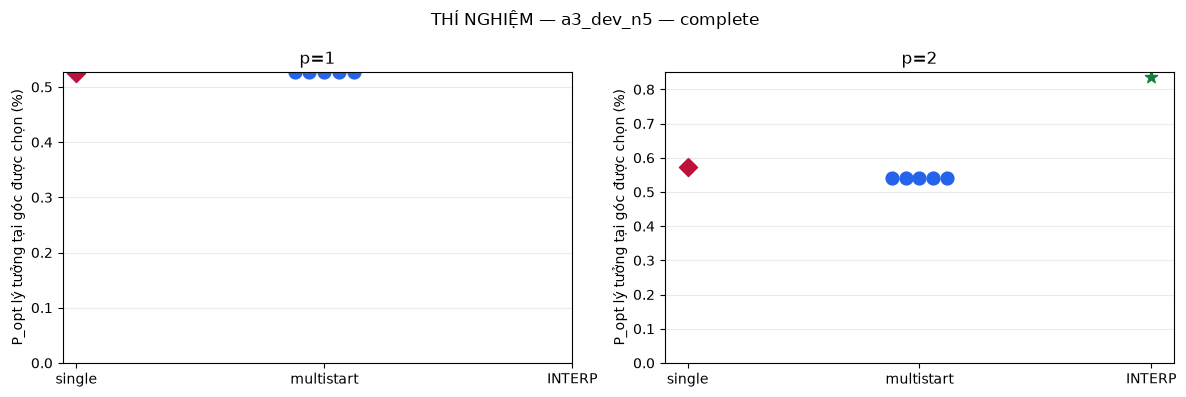

In [8]:
done = results[results['status'].eq('completed')]
if done.empty:
    print('Chưa có kết quả chiến lược hoàn tất để vẽ.')
else:
    depths = protocol['depths']
    fig,axes = plt.subplots(1,len(depths),figsize=(6*len(depths),4),squeeze=False)
    styles = [('single','#be123c','D'),('multistart','#2563eb','o'),('interp','#15803d','*')]
    for ax,p in zip(axes[0],depths):
        found = False
        for i,(strategy,color,marker) in enumerate(styles):
            values = done[done['target_depth'].eq(p)&done['strategy'].eq(strategy)]
            if values.empty:
                continue
            found = True
            offsets = np.linspace(-.12,.12,len(values)) if len(values)>1 else [0]
            ax.scatter(i+np.asarray(offsets),100*values['p_opt'],s=85,color=color,marker=marker,label=strategy)
        if not found:
            ax.text(.5,.5,'Chưa có nhóm hoàn tất',ha='center',transform=ax.transAxes)
        ax.set_xticks(range(3),['single','multistart','INTERP'])
        ax.set_title(f'p={p}')
        ax.set_ylabel('P_opt lý tưởng tại góc được chọn (%)')
        ax.set_ylim(bottom=0)
        ax.grid(axis='y',alpha=.25)
    label = 'KIỂM THỬ PHẦN MỀM' if summary['software_validation'] else 'THÍ NGHIỆM'
    fig.suptitle(label+' — a3_dev_n5 — '+summary['status'])
    fig.tight_layout()
    fig.savefig(CAMPAIGN_DIR/'initialization_popt.png',dpi=160)
    plt.show()

## 8. Audit và xuất ZIP

Audit kiểm nguồn/input, kế hoạch, nfev từng lượt/tổng mỗi chiến lược, điểm random, liên kết INTERP và counts; tính lại xác suất tại các góc cuối. Có thể mất thêm thời gian ở 25 qubit. PASS kiểm tính nhất quán; complete=True xác nhận đủ 13 kết quả/24 lượt của kế hoạch chính. Các giá trị này không chứng minh chất lượng đã tăng.

Lưu notebook có output, gửi cùng init_<timestamp>.zip. Đọc docs/notebook23_initialization_vi.md trước khi kết luận. Kết quả chỉ áp dụng cho bộ quy chiếu và phạm vi khởi tạo đã khảo sát.

In [9]:
RESULT_ZIP = export_campaign(ROOT,CAMPAIGN_DIR)
audit = load_json(CAMPAIGN_DIR/'audit.json')
print('audit:',audit['status'],'| complete:',audit['complete'])
print('coverage:',audit['coverage'])
print('Gửi file ZIP:',RESULT_ZIP)
if not audit['complete']:
    print('Kế hoạch còn partial; chưa kết luận từ tập nhóm chưa đủ.')

audit: PASS | complete: True
coverage: {'planned': 13, 'completed': 13, 'failed': 0, 'pending': 0}
Gửi file ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4o_initialization\init_20261023T133621908469Z.zip
